#### Import libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Configure pandas display
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 20)

# Create output directory if it doesn't exist
Path("output").mkdir(exist_ok=True)

print("Libraries imported successfully!")


Libraries imported successfully!


#### Load the Excel workbook

In [4]:
# Load Excel workbook and check available sheets

file_path = "data/assignment.xlsx"

excel_file = pd.ExcelFile(file_path)

print("Available sheets:")
print(excel_file.sheet_names)

Available sheets:
['Questions', 'Table 1 & 2', 'Table 3']


In [5]:
# Load Table 3 from the Excel workbook

df = pd.read_excel(
    "data/assignment.xlsx",
    sheet_name="Table 3"
)

# Display first 5 records
display(df.head())

# Display dataset dimensions
print("Dataset Shape:", df.shape)

# Display column names
print("\nColumn Names:")
print(df.columns.tolist())


,Sn,CustomerID,StartDate,EndDate,Status,MonthlyRevenue,Region,PlanType,LastLogin,SupportTickets,NPS,Unnamed: 11
0,1,CUST1000,2021-04-13,2022-12-11,Churned,499,West,Premium,2025-06-22 12:28:48.721,2,7,0.0
1,2,CUST1001,2022-03-12,2023-11-05,Churned,199,West,Enterprise,2025-07-24 12:28:48.721,1,6,NaN
2,3,CUST1002,2023-05-11,2025-03-16,Churned,499,North,Basic,2025-06-23 12:28:48.721,1,8,NaN
3,4,CUST1003,2021-09-28,NaT,Active,799,West,Premium,2025-06-22 12:28:48.721,1,3,NaN
4,5,CUST1004,2021-04-17,NaT,Active,299,North,Basic,2025-07-18 12:28:48.721,2,1,NaN


Dataset Shape: (200, 12)

Column Names:
['Sn', 'CustomerID', 'StartDate', 'EndDate', 'Status', 'MonthlyRevenue', 'Region', 'PlanType', 'LastLogin', 'SupportTickets', 'NPS', 'Unnamed: 11']


In [6]:
# Understand data types and non-null values
df.info()

# Check missing values
print("\nMissing Values:")
display(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

# Generate statistical summary
display(df.describe(include="all"))


<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Sn              200 non-null    int64         
 1   CustomerID      200 non-null    str           
 2   StartDate       200 non-null    datetime64[us]
 3   EndDate         106 non-null    datetime64[us]
 4   Status          200 non-null    str           
 5   MonthlyRevenue  200 non-null    int64         
 6   Region          200 non-null    str           
 7   PlanType        200 non-null    str           
 8   LastLogin       200 non-null    datetime64[us]
 9   SupportTickets  200 non-null    int64         
 10  NPS             200 non-null    int64         
 11  Unnamed: 11     1 non-null      float64       
dtypes: datetime64[us](3), float64(1), int64(4), str(4)
memory usage: 18.9 KB

Missing Values:


Sn                  0
CustomerID          0
StartDate           0
EndDate            94
Status              0
MonthlyRevenue      0
Region              0
PlanType            0
LastLogin           0
SupportTickets      0
NPS                 0
Unnamed: 11       199
dtype: int64


Duplicate Records: 0


,Sn,CustomerID,StartDate,EndDate,Status,MonthlyRevenue,Region,PlanType,LastLogin,SupportTickets,NPS,Unnamed: 11
count,200.000000,200,200,106,200,200.00000,200,200,200,200.000000,200.000000,1.0
unique,NaN,200,NaN,NaN,2,NaN,4,4,NaN,NaN,NaN,NaN
top,NaN,CUST1000,NaN,NaN,Churned,NaN,North,Standard,NaN,NaN,NaN,NaN
freq,NaN,1,NaN,NaN,106,NaN,59,56,NaN,NaN,NaN,NaN
mean,100.500000,NaN,2022-04-05 11:31:12,2023-05-11 00:13:35.094339,NaN,587.00000,NaN,NaN,2025-07-01 10:26:24.723294,1.660000,4.930000,0.0
min,1.000000,NaN,2021-01-02 00:00:00,2021-05-26 00:00:00,NaN,199.00000,NaN,NaN,2025-06-03 12:28:48.721000,0.000000,0.000000,0.0
25%,50.750000,NaN,2021-08-05 18:00:00,2022-09-10 06:00:00,NaN,299.00000,NaN,NaN,2025-06-16 12:28:48.722000,1.000000,2.000000,0.0
50%,100.500000,NaN,2022-04-14 12:00:00,2023-04-06 12:00:00,NaN,499.00000,NaN,NaN,2025-06-29 12:28:48.722500,2.000000,5.000000,0.0
75%,150.250000,NaN,2022-12-08 06:00:00,2024-04-03 06:00:00,NaN,999.00000,NaN,NaN,2025-07-15 12:28:48.723000,2.000000,8.000000,0.0
max,200.000000,NaN,2023-06-19 00:00:00,2025-05-04 00:00:00,NaN,999.00000,NaN,NaN,2025-07-31 12:28:48.722000,6.000000,10.000000,0.0


#### Inspect the suspicious column

In [8]:
# Inspect the unnamed column before deciding what to do
print("Non-empty values in Unnamed: 11:")

display(
    df.loc[df["Unnamed: 11"].notna(),
           ["CustomerID", "Status", "Unnamed: 11"]]
)


Non-empty values in Unnamed: 11:


,CustomerID,Status,Unnamed: 11
0,CUST1000,Churned,0.0


#### Clean the dataset

In [10]:
# Create a copy for cleaning
df_clean = df.copy()

# Remove accidental Excel column
df_clean = df_clean.drop(columns=["Unnamed: 11"])

# Remove leading/trailing whitespace from text columns
text_columns = df_clean.select_dtypes(include=["object", "str"]).columns

for col in text_columns:
    df_clean[col] = df_clean[col].str.strip()

# Standardize status values
df_clean["Status"] = df_clean["Status"].str.title()

# Ensure date columns have datetime format
date_columns = ["StartDate", "EndDate", "LastLogin"]

for col in date_columns:
    df_clean[col] = pd.to_datetime(df_clean[col], errors="coerce")

# Check cleaned data
print("Cleaned Dataset Shape:", df_clean.shape)
print("\nMissing Values:")
display(df_clean.isnull().sum())

print("\nDuplicate Records:", df_clean.duplicated().sum())


Cleaned Dataset Shape: (200, 11)

Missing Values:


Sn                 0
CustomerID         0
StartDate          0
EndDate           94
Status             0
MonthlyRevenue     0
Region             0
PlanType           0
LastLogin          0
SupportTickets     0
NPS                0
dtype: int64


Duplicate Records: 0


#### Monthly Churn Analysis

In [12]:
# Filter customers who have churned
churned_customers = df_clean[
    (df_clean["Status"] == "Churned") &
    (df_clean["EndDate"].notna())
].copy()

# Group churned customers by month
monthly_churn = (
    churned_customers
    .set_index("EndDate")
    .resample("MS")["CustomerID"]
    .nunique()
)

# Display monthly churn count
monthly_churn_df = monthly_churn.reset_index()

monthly_churn_df.columns = [
    "Month",
    "Churned Customers"
]

display(monthly_churn_df)

print("Total Churned Customers:", monthly_churn.sum())


,Month,Churned Customers
0,2021-05-01,1
1,2021-06-01,1
2,2021-07-01,0
3,2021-08-01,1
4,2021-09-01,2
...,...,...
44,2025-01-01,1
45,2025-02-01,1
46,2025-03-01,1
47,2025-04-01,0


Total Churned Customers: 106


#### Visualize monthly churn trend Visualization

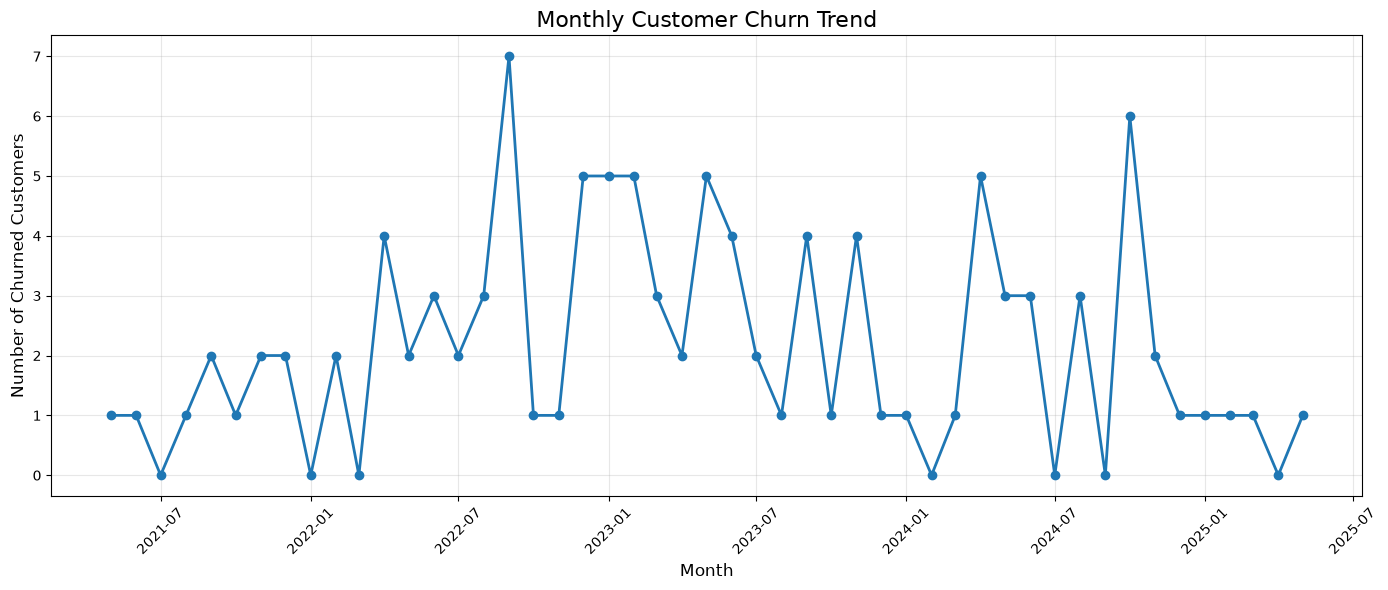

Chart saved successfully!


In [14]:

# Plot monthly churn trend

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_churn.index,
    monthly_churn.values,
    marker="o",
    linewidth=2
)

plt.title("Monthly Customer Churn Trend", fontsize=16)
plt.xlabel("Month", fontsize=12)
plt.ylabel("Number of Churned Customers", fontsize=12)

plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()

# Save visualization
plt.savefig(
    "output/monthly_churn_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart saved successfully!")


### Conclusion – Q5: Data Cleaning and Monthly Churn Analysis

**Data Cleaning:**
- Loaded the customer dataset from the Table 3 worksheet.
- Identified and checked missing values.
- Removed the irrelevant unnamed column.
- Standardized text fields and converted date columns into datetime format.
- Checked for duplicate records; no duplicates were found.
- Preserved missing EndDate values for active customers.

**Churn Analysis:**
- Total customers: 200
- Churned customers: 106
- Active customers: 94
- Monthly churn was calculated using the EndDate column.
- September 2022 recorded the highest churn, with 7 customers.
- The monthly churn trend was visualized using Matplotlib.

**Business Insight:**

Customer churn was relatively high during several periods in 2022–2024, with a lower number of churned customers in the final months of the dataset. Further investigation into customer feedback, support tickets, and plan types could help identify the reasons behind churn.